# Parte 1 – Reconstrucción de las marcas del ecógrafo

Durante el estudio, el ecografista dibuja **marcas** sobre la imagen: cruces para medir la lesión (*calipers*), líneas punteadas entre ellas, textos con la ubicación (por ejemplo "RT AXILLA") y recuadros. El equipo las "quema" en la imagen al guardarla, así que en BUSI **reemplazan los píxeles de tejido** que había debajo.

**Por qué hay que sacarlas.** No son tejido, pero el análisis las trataría como si lo fueran:
- en la caracterización del ruido (Parte 2) agregan valores que no son speckle;
- en los mapas de textura (Parte 4) aparecen como puntos de contraste muy alto, que la segmentación puede confundir con bordes;
- cuando caen sobre el borde del tumor (pasa seguido, porque justamente miden la lesión), alteran sus descriptores (Parte 6).

Esta limpieza **no reduce el speckle**: saca estructuras que no pertenecen a la imagen ecográfica. Corresponde al paso de **reconstrucción** de la consigna.

**Contenido**
1. Cómo son las marcas
2. ¿Alcanza con buscar el blanco puro?
3. Detección con transformada *top-hat* (próximo paso)
4. Reconstrucción con *inpainting* (próximo paso)
5. Validación con marcas sintéticas (próximo paso)

### Preparación

Igual que en las partes anteriores: le decimos a Python dónde está nuestro código (`src/`) e importamos lo que vamos a usar.

In [7]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
import numpy as np
import matplotlib.pyplot as plt

from busi.datos import listar_casos, cargar_caso
from busi import artefactos

casos = listar_casos().set_index("id")     # indexamos por nombre para poder pedir un caso: casos.loc["benign (252)"]

## 1. Cómo son las marcas

Elegimos tres imágenes donde las marcas se ven bien: dos con *calipers* y texto, y una con texto solamente.

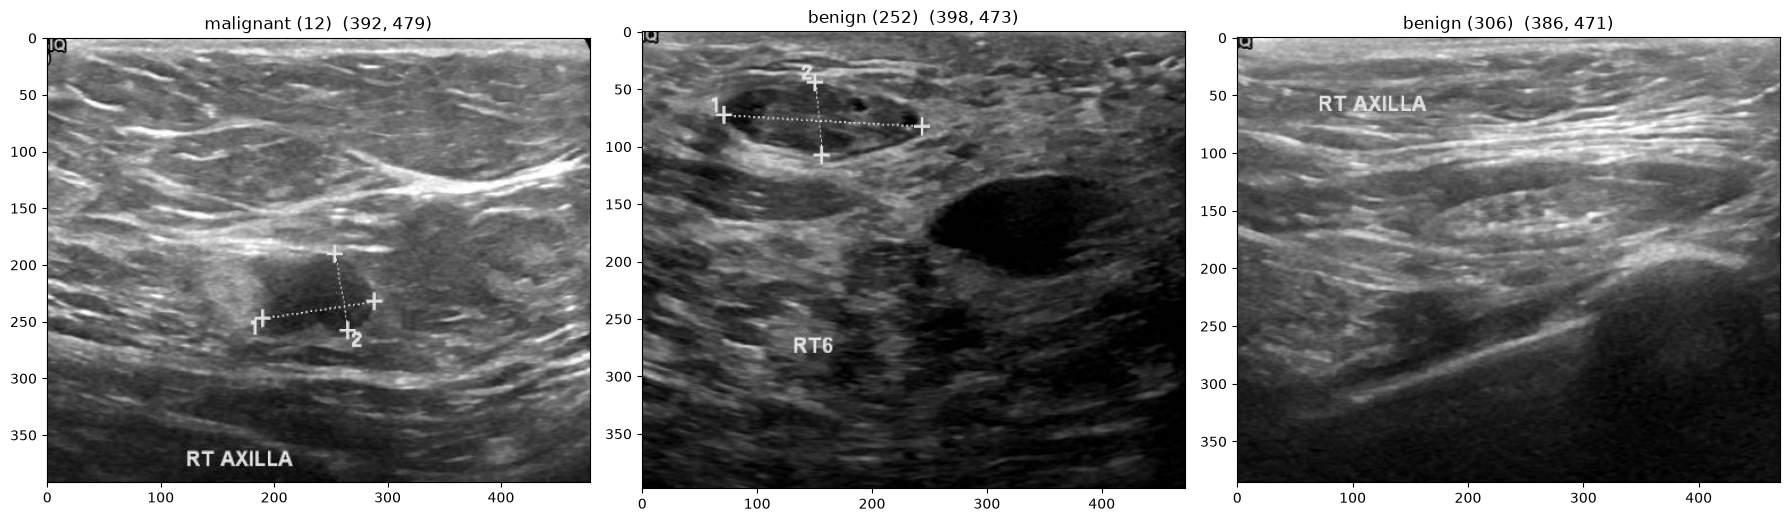

In [9]:
ejemplos = ["malignant (12)", "benign (252)", "benign (306)"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, id_caso in zip(axes, ejemplos):
    img, mascara = cargar_caso(casos.loc[id_caso])
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{id_caso}  {img.shape}")
plt.tight_layout()
plt.show()

Para ver cómo están hechas, hacemos **zoom** sobre las cruces de `malignant (12)`. Con `interpolation="nearest"` cada píxel se dibuja como un cuadradito, sin suavizar, así se ve el tamaño real de las marcas.

Para **medir** su grosor (y no estimarlo a ojo) usamos un **perfil de intensidad**: tomamos los píxeles que están sobre una línea que **cruza** la marca y graficamos el nivel de gris de cada uno. Es como caminar atravesando la cruz y anotar el gris en cada paso: mientras estamos sobre tejido el valor es bajo, al pisar la marca sube, y al salir vuelve a bajar. **El grosor de la marca es la cantidad de píxeles en los que el valor queda alto.**

Medimos dos perfiles:
- **rojo:** una línea horizontal que cruza el brazo **vertical** de la cruz de arriba;
- **celeste:** una línea vertical que cruza el brazo **horizontal** de la cruz de la derecha.

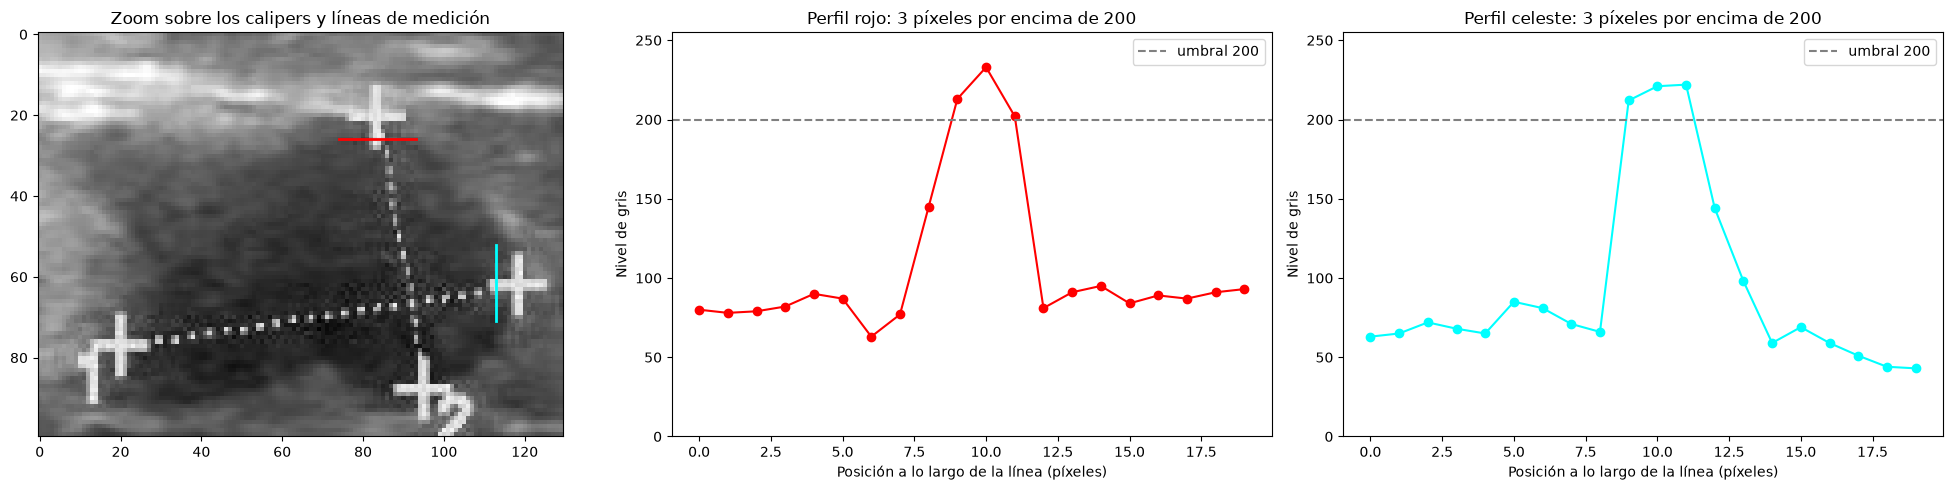

Perfil rojo:    [80, 78, 79, 82, 90, 87, 63, 77, 145, 213, 233, 202, 81, 91, 95, 84, 89, 87, 91, 93]
Perfil celeste: [63, 65, 72, 68, 65, 85, 81, 71, 66, 212, 221, 222, 144, 98, 59, 69, 59, 51, 44, 43]

En todo el recorte: 932 píxeles >= 200, de los cuales solo 13 valen 255


In [10]:
img, mascara = cargar_caso(casos.loc["malignant (12)"])
recorte = img[170:270, 170:300]            # filas 170 a 270, columnas 170 a 300: la zona de las cruces

perfil_rojo = recorte[26, 74:94]           # fila 26, columnas 74 a 93
perfil_celeste = recorte[52:72, 113]       # columna 113, filas 52 a 71
UMBRAL = 200                               # sobre estas dos líneas el tejido no supera ~150; las marcas sí superan 200

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].imshow(recorte, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axes[0].plot([74, 93], [26, 26], color="red", linewidth=2)
axes[0].plot([113, 113], [52, 71], color="cyan", linewidth=2)
axes[0].set_title("Zoom sobre los calipers y líneas de medición")

for ax, perfil, color, nombre in [(axes[1], perfil_rojo, "red", "rojo"),
                                  (axes[2], perfil_celeste, "cyan", "celeste")]:
    ax.plot(perfil, "o-", color=color)
    ax.axhline(UMBRAL, color="gray", linestyle="--", label=f"umbral {UMBRAL}")
    ax.set_ylim(0, 255)
    ax.set_xlabel("Posición a lo largo de la línea (píxeles)")
    ax.set_ylabel("Nivel de gris")
    ax.set_title(f"Perfil {nombre}: {(perfil >= UMBRAL).sum()} píxeles por encima de {UMBRAL}")
    ax.legend()
plt.tight_layout()
plt.show()

print("Perfil rojo:   ", perfil_rojo.tolist())
print("Perfil celeste:", perfil_celeste.tolist())
print(f"\nEn todo el recorte: {(recorte >= 200).sum()} píxeles >= 200, de los cuales solo {(recorte == 255).sum()} valen 255")

**Qué vemos:**
- En los dos perfiles el tejido está entre ~60 y ~100; al cruzar la marca el valor **salta a 210–233 durante exactamente 3 píxeles** y vuelve a bajar. Las marcas son estructuras **muy finas: 3 píxeles de grosor**. A los costados hay un píxel de transición (145 en el perfil rojo, 144 en el celeste), porque el equipo suaviza el borde del dibujo.
- **Los valores de la marca no son 255**: el máximo es 233. En todo el recorte hay 932 píxeles por encima de 200 y solo 13 valen 255.
- Además de las cruces aparecen **números** ("1", "2") que identifican cada medición, del mismo grosor y brillo.

Las marcas se reconocen entonces por dos cosas: son **finas** (3 px) y tienen **mucho contraste con su vecindad inmediata** (saltan más de 100 niveles de gris respecto del tejido de al lado). Esas dos propiedades son las que vamos a usar para detectarlas.

## 2. ¿Alcanza con buscar el blanco puro?

En la Parte 0 vimos que 620 de las 780 imágenes llegan al valor 255 y supusimos que el blanco puro "muchas veces" eran marcas. Lo verificamos: pintamos de **rojo** los píxeles con valor ≥ 250 en cuatro imágenes.

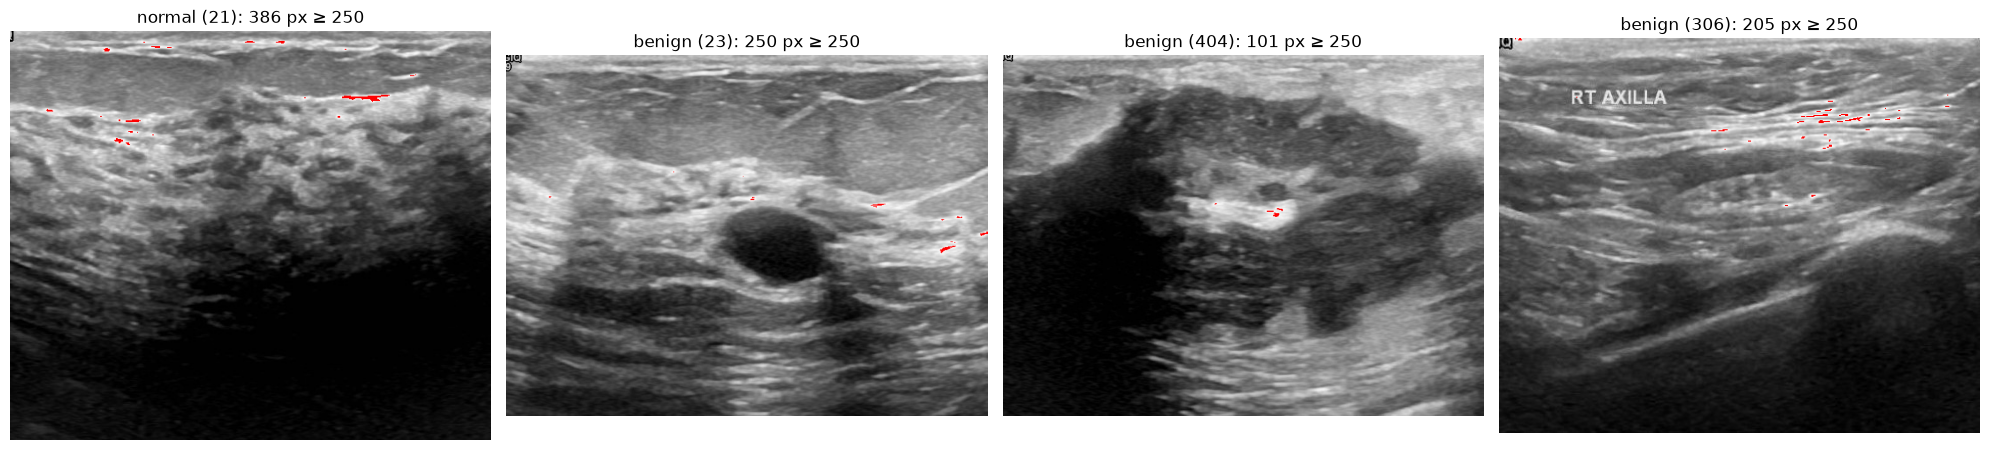

In [11]:
def pintar(img, seleccion, color=(255, 0, 0)):
    """Imagen en RGB con los píxeles de `seleccion` pintados de `color`."""
    rgb = np.dstack([img, img, img])      # gris -> 3 canales iguales
    rgb[seleccion] = color
    return rgb

ejemplos_sat = ["normal (21)", "benign (23)", "benign (404)", "benign (306)"]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, id_caso in zip(axes, ejemplos_sat):
    img, mascara = cargar_caso(casos.loc[id_caso])
    saturados = img >= 250
    ax.imshow(pintar(img, saturados))
    ax.set_title(f"{id_caso}: {saturados.sum()} px ≥ 250")
    ax.axis("off")
plt.tight_layout()
plt.show()

Y contamos en todo el dataset cuántos píxeles saturados tiene cada imagen:

In [12]:
n_saturados = []
for id_caso, caso in casos.iterrows():
    img, mascara = cargar_caso(caso)
    n_saturados.append((img >= 250).sum())
n_saturados = np.array(n_saturados)

print(f"Imágenes sin ningún píxel >= 250:     {(n_saturados == 0).sum()} de {len(casos)}")
print(f"Imágenes con 50 o más píxeles >= 250: {(n_saturados >= 50).sum()} de {len(casos)}")
print(f"Mediana de píxeles >= 250 por imagen: {np.median(n_saturados):.0f}")

Imágenes sin ningún píxel >= 250:     119 de 780
Imágenes con 50 o más píxeles >= 250: 491 de 780
Mediana de píxeles >= 250 por imagen: 110


**Qué vemos:**
- Los píxeles saturados (rojo) están casi siempre en **tejido muy brillante**: la línea de la piel arriba de todo, fibras, ligamentos y zonas de tejido muy ecogénico. **No** son marcas.
- Al revés, el texto "RT AXILLA" de `benign (306)` **casi no aparece en rojo**: es gris claro (~200), no blanco puro.
- 661 de las 780 imágenes tienen algún píxel ≥ 250 y 491 tienen 50 o más. Si todo eso fueran marcas, casi todas las imágenes estarían llenas de marcas, y no es lo que se ve.

**Conclusión:** un **umbral de intensidad no sirve** para detectar marcas. Borraría tejido brillante real (piel, fibras) y dejaría pasar marcas grises (texto, líneas punteadas). Esto **corrige lo que supusimos en la Parte 0**: el blanco puro no es sinónimo de marca. También afecta a la Parte 2, que excluía de los parches los píxeles ≥ 250 para evitar marcas; ese filtro descarta tejido brillante y no detecta las marcas grises (la Parte 2 ya lo menciona como limitación).

Necesitamos un criterio que use **la forma** (marcas finas) y el **contraste local** (mucho más claras que su vecindad inmediata), no el brillo absoluto. Eso es lo que hace la transformada **top-hat**, el próximo paso.